In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from collections import Counter
import re

In [ ]:
df = pd.read_csv('data/data_judi_online_komentar_youtube.csv')

print("=== Info Dataset ===")
df.info()

print("\n=== Jumlah Missing Values ===")
print(df.isnull().sum())

print("\n=== Distribusi Label ===")
print(df['label'].value_counts())

[Output tidak disertakan pada rilis publik. Hanya statistik agregat yang dipublikasikan; teks pesan pengguna, daftar frekuensi kata, dan identitas pengguna dihilangkan. Lihat 'Data & Content Policy' di README.]


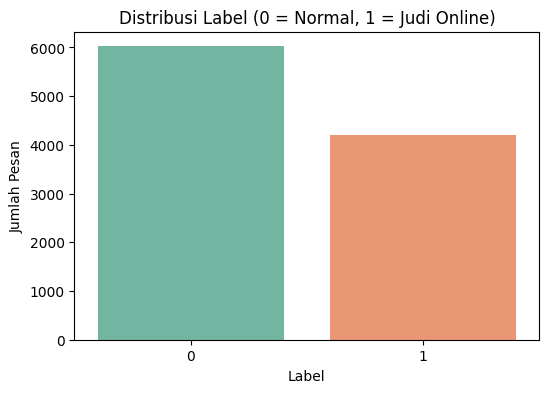

In [ ]:
plt.figure(figsize=(6, 4))
sns.countplot(data=df, x='label', hue='label', palette='Set2', legend=False)
plt.title('Distribusi Label (0 = Normal, 1 = Judi Online)')
plt.xlabel('Label')
plt.ylabel('Jumlah Pesan')
plt.show()

In [ ]:
top_authors_0 = df[df['label'] == 0]['author'].value_counts().head(10)
top_authors_1 = df[df['label'] == 1]['author'].value_counts().head(10)

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# Pesan Normal
sns.barplot(x=top_authors_0.values, y=top_authors_0.index, ax=axes[0], color='skyblue')
axes[0].set_title('Top 10 Author - Pesan Normal (Label 0)')
axes[0].set_xlabel('Jumlah Pesan')

# Pesan Judi Online
sns.barplot(x=top_authors_1.values, y=top_authors_1.index, ax=axes[1], color='salmon')
axes[1].set_title('Top 10 Author - Spam Judi Online (Label 1)')
axes[1].set_xlabel('Jumlah Pesan')

plt.tight_layout()
plt.show()

[Output tidak disertakan pada rilis publik. Hanya statistik agregat yang dipublikasikan; teks pesan pengguna, daftar frekuensi kata, dan identitas pengguna dihilangkan. Lihat 'Data & Content Policy' di README.]


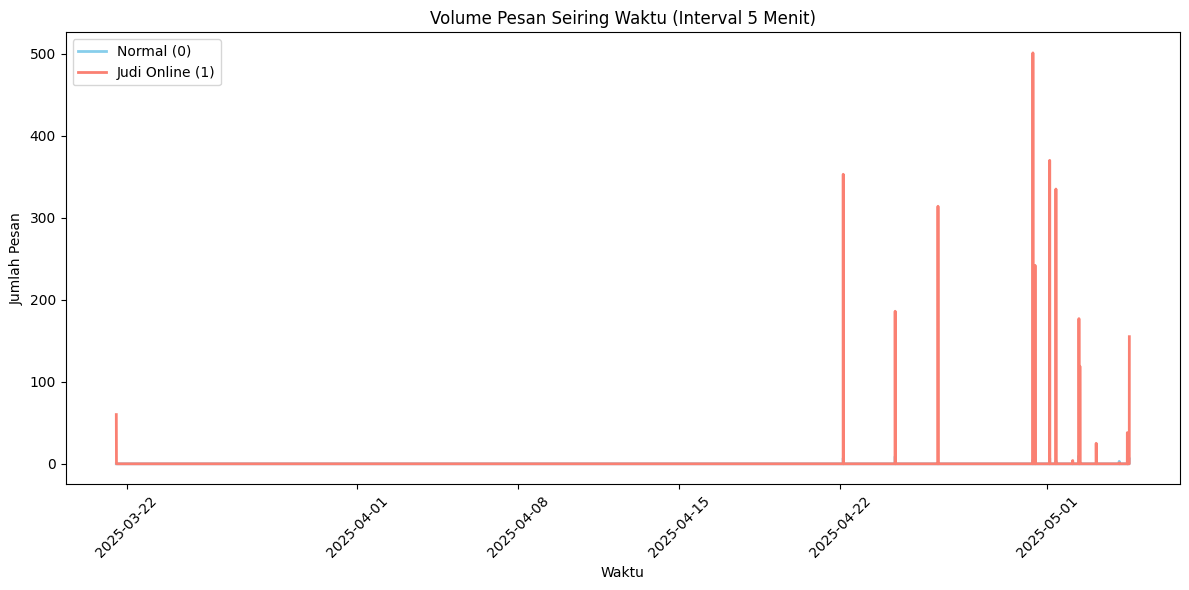

In [ ]:
# Konversi kolom dengan parameter errors='coerce'
df['tanggal'] = pd.to_datetime(df['tanggal'], errors='coerce')

df_clean = df.dropna(subset=['tanggal']).copy()

# Kolom tanggal sebagai index
df_time = df_clean.copy()
df_time.set_index('tanggal', inplace=True)

df_resampled = df_time.groupby('label').resample('5min').size().unstack(level=0, fill_value=0)

plt.figure(figsize=(12, 6))
plt.plot(df_resampled.index, df_resampled[0], label='Normal (0)', color='skyblue', linewidth=2)
plt.plot(df_resampled.index, df_resampled[1], label='Judi Online (1)', color='salmon', linewidth=2)
plt.title('Volume Pesan Seiring Waktu (Interval 5 Menit)')
plt.xlabel('Waktu')
plt.ylabel('Jumlah Pesan')
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [ ]:
def get_top_words(text_series, top_n=20):
    words = ' '.join(text_series.dropna().astype(str).tolist()).lower()
    words = re.findall(r'\b\w+\b', words)
    return Counter(words).most_common(top_n)

# Ekstraksi untuk masing-masing kelas
top_words_0 = get_top_words(df[df['label'] == 0]['komentar_clean'])
top_words_1 = get_top_words(df[df['label'] == 1]['komentar_clean'])

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# Top kata pesan normal
words_0, counts_0 = zip(*top_words_0)
sns.barplot(x=list(counts_0), y=list(words_0), ax=axes[0], color='skyblue')
axes[0].set_title('Top 20 Kata - Pesan Normal')
axes[0].set_xlabel('Frekuensi')

# Top kata spam judi online
words_1, counts_1 = zip(*top_words_1)
sns.barplot(x=list(counts_1), y=list(words_1), ax=axes[1], color='salmon')
axes[1].set_title('Top 20 Kata - Spam Judi Online')
axes[1].set_xlabel('Frekuensi')

plt.tight_layout()
plt.show()

[Output tidak disertakan pada rilis publik. Hanya statistik agregat yang dipublikasikan; teks pesan pengguna, daftar frekuensi kata, dan identitas pengguna dihilangkan. Lihat 'Data & Content Policy' di README.]


In [ ]:
from sklearn.feature_extraction.text import CountVectorizer

# Ekstrak frasa n-grams
def get_top_phrases(text_series, ngram_range=(2, 3), top_n=20):
    valid_text = text_series.dropna().astype(str)
    
    vectorizer = CountVectorizer(ngram_range=ngram_range)
    X = vectorizer.fit_transform(valid_text)
    
    phrases = vectorizer.get_feature_names_out()
    frequencies = X.sum(axis=0).A1
    
    phrase_freq = list(zip(phrases, frequencies))
    phrase_freq.sort(key=lambda x: x[1], reverse=True)
    
    return phrase_freq[:top_n]

# Ekstraksi
top_phrases_0 = get_top_phrases(df[df['label'] == 0]['komentar_clean'], ngram_range=(2, 3), top_n=20)
top_phrases_1 = get_top_phrases(df[df['label'] == 1]['komentar_clean'], ngram_range=(2, 3), top_n=20)

# Visualisasi
fig, axes = plt.subplots(1, 2, figsize=(16, 7))

phrases_0, counts_0 = zip(*top_phrases_0)
sns.barplot(x=list(counts_0), y=list(phrases_0), ax=axes[0], color='skyblue')
axes[0].set_title('Top 20 Frasa (2-3 Kata) - Pesan Normal')
axes[0].set_xlabel('Frekuensi')
axes[0].set_ylabel('Frasa')

phrases_1, counts_1 = zip(*top_phrases_1)
sns.barplot(x=list(counts_1), y=list(phrases_1), ax=axes[1], color='salmon')
axes[1].set_title('Top 20 Frasa (2-3 Kata) - Spam Judi Online')
axes[1].set_xlabel('Frekuensi')
axes[1].set_ylabel('')

plt.tight_layout()
plt.show()

In [ ]:
# Mengambil 20 contoh acak
normal_msgs = df[df['label'] == 0]['komentar'].dropna().sample(10, random_state=42).tolist()
judi_msgs = df[df['label'] == 1]['komentar'].dropna().sample(10, random_state=42).tolist()

# Menampilkan Pesan Normal
print("=== 10 CONTOH PESAN NORMAL (Label 0) ===")
for i, msg in enumerate(normal_msgs, 1):
    print(f"{i}. {msg}")

# Menampilkan Pesan Judi Online
print("\n=== 10 CONTOH SPAM JUDI ONLINE (Label 1) ===")
for i, msg in enumerate(judi_msgs, 1):
    print(f"{i}. {msg}")

[Output tidak disertakan pada rilis publik. Hanya statistik agregat yang dipublikasikan; teks pesan pengguna, daftar frekuensi kata, dan identitas pengguna dihilangkan. Lihat 'Data & Content Policy' di README.]
